# Identifiability Analysis

In [39]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import spearmanr, kendalltau
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (test_progression, TruncateDataframe, ExtractTreatmentFromDf, LoadPatientData, predict_at_threshold_ttp,
                     calc_critical_treatment_threshold, GetPatientIDs, calc_delta_benefit, predict_drug_benefit, predict_ct_ttp, calc_average_overshoot)
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf, perform_bootstrap
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [40]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

In [41]:
file_path = os.path.dirname(os.path.abspath("__file__"))
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")


RERUN_FITTING = False

In [42]:
def calc_AT_score(patientId=None, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=0.2, **params)

In [43]:
def plot_2d_identifiability(patient_data_df, base_model, base_params, solver_kws):
    """
    Generates a 2D Profile Likelihood surface for K and turnover.
    """
    print("Computing 2D Profile Likelihood surface...")
    
    # Define the grid resolution (e.g., 30x30 = 900 ODE solves)
    # Adjust these bounds if your typical fits land elsewhere
    k_vals = np.linspace(2.5, 4.0, 30)
    turnover_vals = np.linspace(0.2, 0.6, 30)
    
    sse_grid = np.zeros((len(k_vals), len(turnover_vals)))
    
    # We create a new parameter object to avoid altering your base_params
    test_params = base_params.copy()
    
    # Fix both parameters so the optimizer doesn't move them
    test_params['K'].vary = False
    test_params['turnover'].vary = False

    for i, k in enumerate(k_vals):
        for j, turn in enumerate(turnover_vals):
            test_params['K'].value = k
            test_params['turnover'].value = turn
            
            try:
                # Call your exact residual function
                # Note: If you added 'log_transform': True to residual_kws, pass it here too
                res = residual(test_params, patient_data_df, base_model, "PSA", solver_kws)
                
                # Calculate Sum of Squared Errors
                sse = np.sum(res**2)
                sse_grid[i, j] = sse
            except Exception as e:
                sse_grid[i, j] = np.inf
                
    # --- Plotting ---
    plt.figure(figsize=(10, 8))
    X, Y = np.meshgrid(turnover_vals, k_vals)
    
    # Plot log of SSE to make the minimum visually distinct
    cp = plt.contourf(X, Y, np.log10(sse_grid), levels=40, cmap='viridis_r')
    plt.colorbar(cp, label='Log10(Sum of Squared Errors)')
    
    # Mark the global minimum
    min_idx = np.unravel_index(np.argmin(sse_grid), sse_grid.shape)
    plt.plot(turnover_vals[min_idx[1]], k_vals[min_idx[0]], 'r*', markersize=12, label='Global Optimum')

    patient_id = patient_data_df['PatientId'].iloc[0]
    
    plt.title("Practical Identifiability Contour")
    plt.xlabel("Turnover Rate")
    plt.ylabel("Carrying Capacity (K)")
    plt.tight_layout()
    plt.savefig(f"figures/2d_identifiability_contour_{patient_id}.pdf", dpi=300, bbox_inches='tight')
    plt.close()

## Patient Datasets

Loaded Patient IDs: [12, 20, 25, 78, 85, 99, 101]


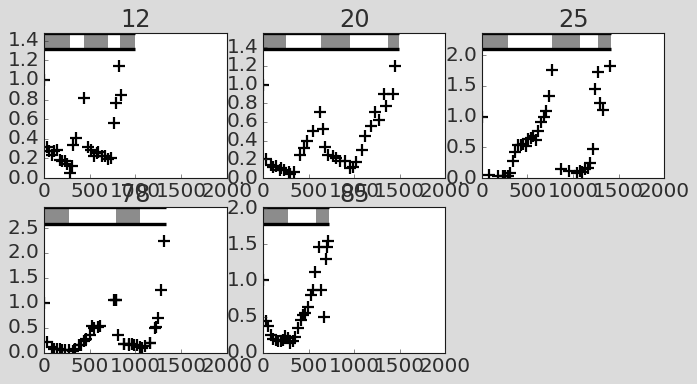

In [44]:
data_path = "../patients/Bruchovsky_et_al/Prog_data_txt"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))
patientIds = patientIds[:-2]  # Exclude two trickiest patients

plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(10, 5))
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');

In [8]:
# patientsToAnalyseList = [20, 78]  
patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# Variable Parameters
params.add('n0', min=0.1, max=1.2, vary=True); 
params.add('fR', min=1e-5, max=0.1, vary=True)
params.add('cost', min=0.1, max=0.5, vary=True)
params.add('turnover', min=0.1, max=1., vary=True)
params.add('K', value=1, min=0.5, max=5, vary=True)
params.add('rS', value=0.027, min=0.01, max=0.04, vary=True);

# Fixed/Calculated Parameters
# params.add('rS', value=0.027, vary=False); 
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [52]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index(drop=True)
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 5/5 [00:38<00:00,  7.61s/it]


In [53]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    data = []
    # Only loop through the patients we know we just processed
    for patientId in patientsToAnalyseList:
        patient_dir = f"patient{patientId}"
        full_path = os.path.join(out_dir, model_name, patient_dir)
        
        if os.path.exists(full_path):
            fitSummaryDf = generate_fitSummaryDf(full_path)
            patient_id_match = re.findall(r'\d+', patient_dir)
            if patient_id_match:
                patient_id = int(patient_id_match[0])
                fitSummaryDf.insert(0, "PatientId", patient_id)
                data.append(fitSummaryDf)

    df = pd.concat(data, axis=0)
        
    df['TimeInTrial'] = df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    df = df.sort_values(by="PatientId").reset_index(drop=True)
    df = df[df['PatientId'].isin(patientIds)]
    df['Cost'] = 1 - df['rR'] / df['rS']; df['Turnover'] = df['dS'] / df['rS']

    print(df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS']])

    #Test progression
    df['Progression'] = df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(df.Progression.sum(), len(df)), end='')
    print(f"  ({[x for x in df.PatientId[df.Progression==True]]})")

    # Save patient params
    df.to_csv("patient_fits/full_history_params.csv", index=False)

else:
    df = pd.read_csv("patient_fits/full_history_params.csv")

   PatientId        n0        fR  Turnover      Cost         K        rS
0         12  0.746495  0.000275  0.100000  0.106716  5.000000  0.013379
1         20  0.689043  0.000520  0.332779  0.100000  1.848765  0.013343
2         25  1.007618  0.000014  0.309618  0.100000  2.882098  0.019771
3         78  0.819158  0.000010  0.309967  0.100000  1.772092  0.022394
4         85  0.975555  0.033058  0.334888  0.429925  4.999988  0.028906
Progression: 5/5  ([12, 20, 25, 78, 85])


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_44316/634188963.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(data, axis=0)


In [54]:
n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/AT_Benefit_Prediction/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwargs.get(key, self.paramDic[key]))
/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/AT_Benefit_Prediction/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwargs.get(key, self.paramDic[key]))
/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/AT_Benefit_Prediction/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwargs.get(

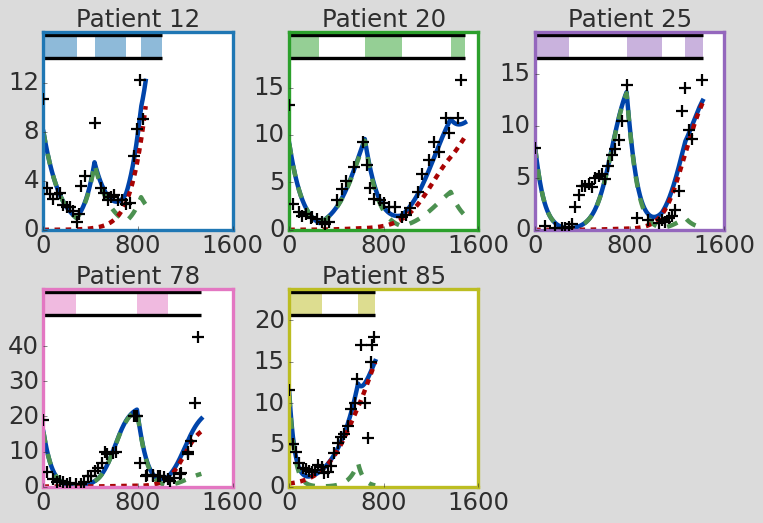

In [55]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(10, 7))
for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    psa_scale = dataDf.PSA_raw[0]
    dataDf.PSA = dataDf.PSA * psa_scale
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    
    if patientId in patientsToAnalyseList:
        params = df[df.PatientId == patientId]
        myModel=LotkaVolterraModel()
        myModel.SetParams(**params)
        myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
        myModel.Trim(dt=1)
        
        linestyles = ['-', (0, (10,10)), (0, (5,5))]
        col_vars = ['AT', 'Sensitive', 'Resistant']
        df_temp = myModel.resultsDf[myModel.resultsDf.TumourSize < max(dataDf.PSA) / psa_scale] 
        for j, var in enumerate(["TumourSize", 'S', 'R']):
            ax.plot(df_temp['Time'], df_temp[var]*psa_scale, linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])

        ax.legend().remove()
    ax.set_title("Patient " +str(patientId), size=22); 
    ax.set_xticks([0, 800, 1600]); ax.set_xlim(0, 1600)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7: ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Bruchovsky_summary.pdf", dpi=300, bbox_inches='tight')

In [56]:

def plot_full_6param_profiles_safe(patient_data_df, base_model, base_params, solver_kws, optimiser_kws, residual_kws={}, grid_size=15):
    print("Running 1D Profile Likelihoods with telemetry...")
    
    params_to_profile = ['n0', 'fR', 'cost', 'turnover', 'K', 'rS']
    
    safe_optimiser_kws = optimiser_kws.copy()
    safe_optimiser_kws['max_nfev'] = 150  
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, param_name in enumerate(params_to_profile):
        print(f"\n--- Profiling {param_name} ---")
        
        p_min = base_params[param_name].min
        p_max = base_params[param_name].max
        
        if p_min == -np.inf or p_min is None: p_min = 0.001
        if p_max == np.inf or p_max is None: p_max = 5.0
        
        # PREVENT ODE CRASH: Ensure K doesn't drop below starting volume
        if param_name == 'K': 
            p_min = max(1.1, p_min)  
            
        param_vals = np.linspace(p_min, p_max, grid_size)
        sses, at_scores, valid_vals = [], [], []
        
        for p_val in param_vals:
            print(f"  -> Testing {p_val:.4f}...", end=" ", flush=True)
            
            test_params = base_params.copy()
            test_params[param_name].value = p_val
            test_params[param_name].vary = False
            
            for other_param in params_to_profile:
                if other_param != param_name: test_params[other_param].vary = True
                    
            try:
                fit_obj = minimize(residual, test_params, 
                                   args=(patient_data_df, base_model, "PSA", solver_kws, residual_kws), 
                                   **safe_optimiser_kws)
                
                res_array = residual(fit_obj.params, patient_data_df, base_model, "PSA", solver_kws, residual_kws)
                sse = np.sum(res_array**2)
                score = calc_AT_score(patientId=0, **fit_obj.params.valuesdict())
                
                sses.append(sse)
                at_scores.append(score)
                valid_vals.append(p_val)
                print(f"Done. (SSE: {sse:.2f})")
                
            except Exception as e:
                print(f"Skipped.")
        
        ax1 = axes[idx]
        color1 = 'tab:blue'
        ax1.set_xlabel(param_name)
        ax1.set_ylabel('Sum of Squared Errors', color=color1)
        ax1.plot(valid_vals, sses, color=color1, linewidth=2, marker='o', markersize=4)
        ax1.tick_params(axis='y', labelcolor=color1)
        
        if len(sses) > 0: ax1.set_ylim([min(sses) * 0.95, max(sses) * 1.05])
        
        ax2 = ax1.twinx()  
        color2 = 'tab:red'
        ax2.set_ylabel('Predicted AT Score', color=color2)
        ax2.plot(valid_vals, at_scores, color=color2, linestyle='--', linewidth=3)
        ax2.tick_params(axis='y', labelcolor=color2)
        
        # PREVENT MATPLOTLIB CRASH: Filter NaNs
        valid_at_scores = [s for s in at_scores if np.isfinite(s)]
        if len(valid_at_scores) > 0:
            mean_at = np.mean(valid_at_scores)
            ax2.set_ylim([mean_at - 0.1, mean_at + 0.1])
            
        ax1.set_title(f"Profile: {param_name}")

    fig.tight_layout()
    plt.show()

Loading data and preparing profile for Patient 12...
Running 1D Profile Likelihoods with telemetry...

--- Profiling n0 ---
  -> Testing 0.1000... Done. (SSE: 1.99)
  -> Testing 0.1786... Done. (SSE: 1.63)
  -> Testing 0.2571... Done. (SSE: 1.35)
  -> Testing 0.3357... Done. (SSE: 1.10)
  -> Testing 0.4143... Done. (SSE: 0.90)
  -> Testing 0.4929... Done. (SSE: 0.75)
  -> Testing 0.5714... Done. (SSE: 0.65)
  -> Testing 0.6500... Done. (SSE: 0.59)
  -> Testing 0.7286... Done. (SSE: 0.57)
  -> Testing 0.8071... Done. (SSE: 0.58)
  -> Testing 0.8857... Done. (SSE: 0.60)
  -> Testing 0.9643... Done. (SSE: 0.65)
  -> Testing 1.0429... 

KeyboardInterrupt: 

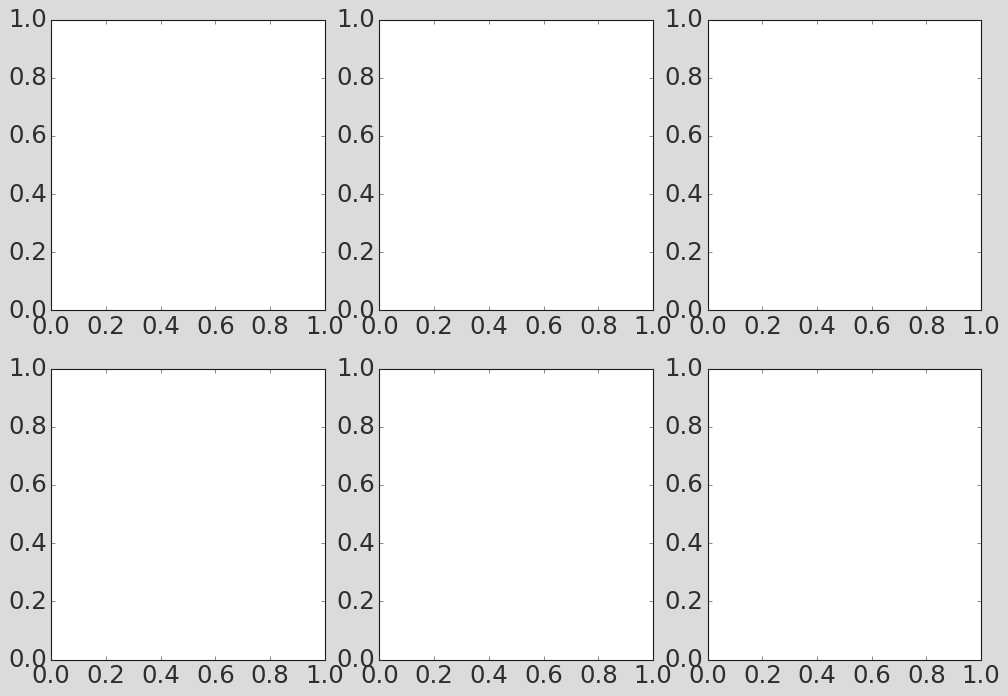

In [57]:

# 1. Specify the patient you want to profile for the SI figure
patient_to_profile = 12

print(f"Loading data and preparing profile for Patient {patient_to_profile}...")

# 2. Point to their specific saved fit object
curr_out_dir = os.path.join(working_dir, f"patient{patient_to_profile}")
fit_obj_path = os.path.join(curr_out_dir, "fitObj_fit_0.p")

# 3. Load the object
try:
    with open(fit_obj_path, "rb") as f:
        fit_obj = pickle.load(f)
        
    # Extract the data directly from the fit object (or use LoadPatientData if you prefer)
    patient_data_df = fit_obj.data
    
    # 4. Ensure you have an instantiated model ready
    tmp_model = LotkaVolterraModel()
    
    # 5. Run the safe profiling function
    plot_full_6param_profiles_safe(
        patient_data_df=patient_data_df, 
        base_model=tmp_model, 
        base_params=fit_obj.params, 
        solver_kws=solver_kws, 
        optimiser_kws=optimiser_kws,
        grid_size=15  # Adjust this to 20 if you want smoother curves later
    )

except FileNotFoundError:
    print(f"Error: Could not find the fit object for Patient {patient_to_profile} at {fit_obj_path}")

In [ ]:
def plot_full_6param_profiles_safe(patient_data_df, base_model, base_params, solver_kws, optimiser_kws, residual_kws={}, grid_size=15, explicit_bounds=None):
    print("Running 1D Profile Likelihoods with strict bounds...")
    
    params_to_profile = ['n0', 'fR', 'cost', 'turnover', 'K', 'rS']
    
    safe_optimiser_kws = optimiser_kws.copy()
    safe_optimiser_kws['max_nfev'] = 150  
    
    if explicit_bounds is None: explicit_bounds = {}
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    for idx, param_name in enumerate(params_to_profile):
        print(f"\n--- Profiling {param_name} ---")
        
        # 1. ENFORCE EXPLICIT BOUNDS
        if param_name in explicit_bounds:
            p_min, p_max = explicit_bounds[param_name]
        else:
            p_min = base_params[param_name].min
            p_max = base_params[param_name].max
            if p_min == -np.inf or p_min is None: p_min = 0.001
            if p_max == np.inf or p_max is None: p_max = 5.0
        
        if param_name == 'K': 
            p_min = max(1.1, p_min)  
            
        param_vals = np.linspace(p_min, p_max, grid_size)
        sses,  valid_vals = [], []
        
        for p_val in param_vals:
            print(f"  -> Testing {p_val:.4f}...", end=" ", flush=True)
            
            test_params = base_params.copy()
            test_params[param_name].value = p_val
            test_params[param_name].vary = False
            
            for other_param in params_to_profile:
                if other_param != param_name: test_params[other_param].vary = True
                    
            try:
                fit_obj = minimize(residual, test_params, 
                                   args=(patient_data_df, base_model, "PSA", solver_kws, residual_kws), 
                                   **safe_optimiser_kws)
                
                res_array = residual(fit_obj.params, patient_data_df, base_model, "PSA", solver_kws, residual_kws)
                sse = np.sum(res_array**2)
            
                sses.append(sse)
                valid_vals.append(p_val)
                print(f"Done. (SSE: {sse:.2f})")
                
            except Exception as e:
                print(f"Skipped.")
        
        # Plotting
        ax1 = axes[idx]
        ax1.set_xlabel(param_name)
        ax1.plot(valid_vals, sses, color='tab:blue', linewidth=2, marker='o', markersize=4)
        ax1.set_xticks(ax1.get_xticks()[::2])
        
        if len(sses) > 0: ax1.set_ylim([min(sses) * 0.95, max(sses) * 1.05])
            
        # ax1.set_title(f"Profile: {param_name}")


    patient_id = patient_data_df['PatientId'].iloc[0]
    fig.tight_layout()
    plt.savefig(f"figures/identifiability_profiles_{patient_id}.pdf", dpi=300, bbox_inches='tight')
    plt.close(fig)

In [ ]:

# 1. Specify the patient you want to profile for the SI figure
for patient_to_profile in [85]:#patientIds:

    print(f"Loading data and preparing profile for Patient {patient_to_profile}...")

    # 2. Point to their specific saved fit object
    curr_out_dir = os.path.join(working_dir, f"patient{patient_to_profile}")
    fit_obj_path = os.path.join(curr_out_dir, "fitObj_fit_0.p")

    # 3. Load the object
    try:
        with open(fit_obj_path, "rb") as f:
            fit_obj = pickle.load(f)
            
        # Extract the data directly from the fit object (or use LoadPatientData if you prefer)
        patient_data_df = fit_obj.data
        
        # 4. Ensure you have an instantiated model ready
        tmp_model = LotkaVolterraModel()
        
        # 5. Run the safe profiling function
        plot_full_6param_profiles_safe(
            patient_data_df=patient_data_df, 
            base_model=tmp_model, 
            base_params=fit_obj.params, 
            solver_kws=solver_kws, 
            optimiser_kws=optimiser_kws,
            grid_size=15  # Adjust this to 20 if you want smoother curves later
        )

    except FileNotFoundError:
        print(f"Error: Could not find the fit object for Patient {patient_to_profile} at {fit_obj_path}")

Loading data and preparing profile for Patient 85...
Running 1D Profile Likelihoods with strict bounds...

--- Profiling n0 ---
  -> Testing 0.1000... Done. (SSE: 1.97)
  -> Testing 0.1786... Done. (SSE: 1.68)
  -> Testing 0.2571... Done. (SSE: 1.47)
  -> Testing 0.3357... Done. (SSE: 1.31)
  -> Testing 0.4143... Done. (SSE: 1.18)
  -> Testing 0.4929... Done. (SSE: 1.08)
  -> Testing 0.5714... Done. (SSE: 0.99)
  -> Testing 0.6500... Done. (SSE: 0.93)
  -> Testing 0.7286... Done. (SSE: 0.88)
  -> Testing 0.8071... Done. (SSE: 0.84)
  -> Testing 0.8857... Done. (SSE: 0.82)
  -> Testing 0.9643... Done. (SSE: 0.81)
  -> Testing 1.0429... Done. (SSE: 0.81)
  -> Testing 1.1214... Done. (SSE: 0.83)
  -> Testing 1.2000... Done. (SSE: 0.86)

--- Profiling fR ---
  -> Testing 0.0000... Done. (SSE: 1.64)
  -> Testing 0.0072... Done. (SSE: 0.93)
  -> Testing 0.0143... Done. (SSE: 0.87)
  -> Testing 0.0214... Done. (SSE: 0.83)
  -> Testing 0.0286... Done. (SSE: 0.81)
  -> Testing 0.0357... Done. (

## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [45]:
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Trunc_fits")

patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-5, vary=False)
params.add('cost', value=0.1, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [46]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()

        last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
        
        training_data_df = training_data_df[:last_cycle1_index+2]
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        plot_2d_identifiability(training_data_df, tmp_model, params, solver_kws)

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

In [47]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    trunc_df = pd.DataFrame()

    for patientId in patientsToAnalyseList:
        patient_dir = f"patient{patientId}"
        full_path = os.path.join(out_dir, model_name, patient_dir)
        
        if os.path.exists(full_path):
            fitSummaryDf = generate_fitSummaryDf(full_path)
            fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
            trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']; 
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']
    trunc_df['K'] = 2.5

    print(trunc_df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS']])

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    # Save patient params
    trunc_df.to_csv("patient_fits/first_cycle_params.csv", index=False)
else:
    trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

## Sensitivity Analysis - K


In [ ]:
k_low_params = trunc_df.copy()
k_low_params['K'] = 2.5
k_high_params = trunc_df.copy()
k_high_params['K'] = 5.0

In [ ]:
def simulate_doubling_time(params):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate([[0, 2000, 0]])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2]
    
    return model.resultsDf.Time.max()

In [ ]:
# Generate a table with patient id, predicted doubling time, and true doubling time
doubling_time_data = []

for patientId in patientIds:
    param_sets = [k_low_params.loc[k_low_params.PatientId == patientId].iloc[0].to_dict(),
                  k_high_params.loc[k_high_params.PatientId == patientId].iloc[0].to_dict()]
    doubling_times = [simulate_doubling_time(param_set) for param_set in param_sets]
    doubling_time_data.append([patientId, doubling_times[0], doubling_times[1]])

doubling_time_df = pd.DataFrame(doubling_time_data, columns=['PatientId', 'Linear Space', 'Log Space'])
print(doubling_time_df)

   PatientId  Linear Space  Log Space
0         12        13.329      9.290
1         20        33.433     15.937
2         25        27.107     14.356
3         78        41.123     17.470
4         85        20.408     12.240


In [ ]:
# 1. Spearman's Rank Correlation
rho, p_spearman = spearmanr(doubling_time_df['Linear Space'], doubling_time_df['Log Space'])

# 2. Kendall's Tau Correlation
tau, p_kendall = kendalltau(doubling_time_df['Linear Space'], doubling_time_df['Log Space'])

# --- Print Results ---
print("--- Robustness of Biomarker Rankings ---")
print(f"Sample Size (N) = {len(doubling_time_df)}")
print(f"Spearman's rho : {rho:.3f} (P = {p_spearman:.4f})")
print(f"Kendall's tau  : {tau:.3f} (P = {p_kendall:.4f})")

--- Robustness of Biomarker Rankings ---
Sample Size (N) = 5
Spearman's rho : 1.000 (P = 0.0000)
Kendall's tau  : 1.000 (P = 0.0167)


In [ ]:
def calc_AT_score(patientId=None, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=0.2, **params)

In [ ]:
# Generate a table with patient id, predicted doubling time, and true doubling time
at_score_list = []

for patientId in patientIds:
    param_sets = [k_low_params.loc[k_low_params.PatientId == patientId].iloc[0].to_dict(),
                  k_high_params.loc[k_high_params.PatientId == patientId].iloc[0].to_dict()]
    at_scores = [calc_AT_score(patientId, **param_set) for param_set in param_sets]
    at_score_list.append([patientId, at_scores[0], at_scores[1]])

at_score_df = pd.DataFrame(at_score_list, columns=['PatientId', 'K=2.5', 'K=5.0'])
print(at_score_df)

   PatientId     K=2.5     K=5.0
0         12  0.270092  0.270091
1         20  0.495319  0.495316
2         25  0.438991  0.438988
3         78  0.551727  0.551723
4         85  0.366395  0.366393


In [ ]:
# 1. Spearman's Rank Correlation
rho, p_spearman = spearmanr(at_score_df['K=2.5'], at_score_df['K=5.0'])

# 2. Kendall's Tau Correlation
tau, p_kendall = kendalltau(at_score_df['K=2.5'], at_score_df['K=5.0'])

# --- Print Results ---
print("--- Robustness of Biomarker Rankings ---")
print(f"Sample Size (N) = {len(at_score_df)}")
print(f"Spearman's rho : {rho:.3f} (P = {p_spearman:.4f})")
print(f"Kendall's tau  : {tau:.3f} (P = {p_kendall:.4f})")

--- Robustness of Biomarker Rankings ---
Sample Size (N) = 5
Spearman's rho : 1.000 (P = 0.0000)
Kendall's tau  : 1.000 (P = 0.0167)


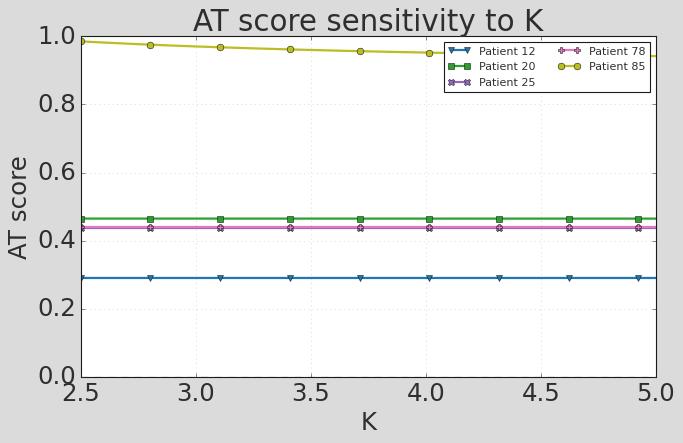

,PatientId,K,AT_score
0,12,2.500000,0.290725
1,12,2.525253,0.290724
2,12,2.550505,0.290724
3,12,2.575758,0.290723
4,12,2.601010,0.290723


In [ ]:
# Sweep K and plot AT score curves per patient
k_range = np.linspace(2.5, 5, 100)

at_vs_k_records = []
fig, ax = plt.subplots(figsize=(9, 6))

for i, patient_id in enumerate(patientIds):
    base_params = df.loc[df["PatientId"] == patient_id].iloc[0].to_dict()
    at_scores = []

    for k in k_range:
        p = base_params.copy()
        p["K"] = k
        try:
            score = calc_AT_score(patient_id, **p)
        except Exception:
            score = np.nan

        at_scores.append(score)
        at_vs_k_records.append({"PatientId": patient_id, "K": k, "AT_score": score})

    ax.plot(
        k_range,
        at_scores,
        color=cols[i],
        marker=markers[i % len(markers)],
        markevery=12,
        linewidth=2,
        label=f"Patient {patient_id}",
    )

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("K")
ax.set_ylabel("AT score")
ax.set_title("AT score sensitivity to K")
ax.legend(ncol=2, fontsize=10)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

at_vs_k_df = pd.DataFrame(at_vs_k_records)
at_vs_k_df.head()

## Profile Likelihood - K

In [ ]:
def plot_1d_profile_overlay_linear(patient_data_df, base_model, base_params, solver_kws, optimiser_kws, residual_kws={}):
    print("Running 1D Profile Likelihood for K (Linear Space)...")
    
    k_vals = np.linspace(2.5, 5.0, 20)
    sses = []
    at_scores = []
    
    for k in k_vals:
        test_params = base_params.copy()
        test_params['K'].value = k
        test_params['K'].vary = False
        test_params['turnover'].vary = True 
        
        # Fit using your standard linear residual
        fit_obj = minimize(residual, test_params, 
                           args=(patient_data_df, base_model, "PSA", solver_kws, residual_kws), 
                           **optimiser_kws)
        
        # Calculate standard Sum of Squared Errors
        res_array = residual(fit_obj.params, patient_data_df, base_model, "PSA", solver_kws, residual_kws)
        sses.append(np.sum(res_array**2))
        
        # Calculate downstream AT score
        at_scores.append(calc_AT_score(**fit_obj.params.valuesdict()))
        
    # --- Plotting ---
    fig, ax1 = plt.subplots(figsize=(10, 7))

    color1 = 'tab:blue'
    ax1.set_xlabel('Carrying Capacity (K)')
    ax1.set_ylabel('Sum of Squared Errors (Linear)', color=color1)
    ax1.plot(k_vals, sses, color=color1, linewidth=4)
    ax1.tick_params(axis='y', labelcolor=color1)
    
    # Prevent matplotlib from forcing the y-axis to 0 if the valley is high up
    ax1.set_ylim([min(sses) * 0.95, max(sses) * 1.05])

    ax2 = ax1.twinx()  
    color2 = 'tab:red'
    ax2.set_ylabel('Predicted AT Score', color=color2)
    ax2.plot(k_vals, at_scores, color=color2, linestyle='--', linewidth=4)
    ax2.tick_params(axis='y', labelcolor=color2)
    
    # Ensure the AT score axis has some breathing room so flat lines don't look jagged
    mean_at = np.mean(at_scores)
    ax2.set_ylim([mean_at - 0.1, mean_at + 0.1])

    plt.title("1D Profile Likelihood & Decision Stability for K")
    fig.tight_layout()
    patient_id = patient_data_df['PatientId'].iloc[0]
    plt.savefig(f"figures/1d_profile_k_linear_{patient_id}.pdf", dpi=300, bbox_inches='tight')
    plt.close(fig)
    # plt.show()

In [ ]:
for patientId in patientIds:
    print(f"\n=== Patient {patientId} ===")

    # Match the first-cycle training slice used in fitting
    patient_data_df = LoadPatientData(patientId, data_path)
    patient_data_df = patient_data_df.dropna(subset=["PSA"]).reset_index()
    last_cycle1_index = patient_data_df[patient_data_df["CycleId"] == 1].index[-1]
    patient_data_df = patient_data_df.iloc[:last_cycle1_index + 2].reset_index(drop=True)

    # Use patient-specific fitted params if available
    fit_path = os.path.join(working_dir, f"patient{patientId}", "fitObj_fit_0.p")
    if os.path.exists(fit_path):
        with open(fit_path, "rb") as f:
            patient_fit_obj = pickle.load(f)
        base_params = patient_fit_obj.params
    else:
        base_params = params  # fallback

    patient_model = LotkaVolterraModel()
    plot_1d_profile_overlay_linear(
        patient_data_df, patient_model, base_params, solver_kws, optimiser_kws
    )


=== Patient 12 ===
Running 1D Profile Likelihood for K (Linear Space)...

=== Patient 20 ===
Running 1D Profile Likelihood for K (Linear Space)...

=== Patient 25 ===
Running 1D Profile Likelihood for K (Linear Space)...

=== Patient 78 ===
Running 1D Profile Likelihood for K (Linear Space)...

=== Patient 85 ===
Running 1D Profile Likelihood for K (Linear Space)...


## Residual Bootstrapping

In [ ]:
bootstrap_df = perform_bootstrap(fitObj=fit_obj, n_bootstraps=100, model_to_observation_map={"TumourSize":'PSA'})

100%|██████████| 100/100 [02:59<00:00,  1.80s/it]


In [ ]:
def calculate_clinical_decision_stability(fitObj, bootstrap_df, base_model, at_threshold=0.40):
    print("Propagating linear parameter uncertainty to clinical biomarkers...")
    
    at_scores = []
    
    for i in range(len(bootstrap_df)):
        # Extract params for this bootstrap
        curr_params = fitObj.params.copy()
        for var in bootstrap_df.columns:
            if var == "SSR": continue
            if var in curr_params:
                curr_params[var].value = bootstrap_df[var].iloc[i]
                
        base_model.SetParams(**curr_params)
        
        score = calc_AT_score(**curr_params.valuesdict())
        at_scores.append(score)
        
    at_scores = np.array(at_scores)
    
    median_at = np.median(at_scores)
    ci_lower = np.percentile(at_scores, 2.5)
    ci_upper = np.percentile(at_scores, 97.5)
    
    # Calculate probability of staying in the AT arm
    prob_at_arm = np.mean(at_scores > at_threshold) * 100
    
    print(f"\nMedian AT Score: {median_at:.3f}")
    print(f"95% CI: ({ci_lower:.3f} - {ci_upper:.3f})")
    print(f"Probability of remaining in AT Arm: {prob_at_arm:.1f}%")
    
    # Plotting the histogram
    plt.figure(figsize=(6, 4))
    plt.hist(at_scores, bins=15, color='lightgray', edgecolor='black')
    plt.axvline(median_at, color='blue', linestyle='solid', linewidth=2, label="Median")
    plt.axvline(ci_lower, color='blue', linestyle='dashed', linewidth=2, label="95% CI")
    plt.axvline(ci_upper, color='blue', linestyle='dashed', linewidth=2)
    if at_threshold:
        plt.axvline(at_threshold, color='red', linestyle='solid', linewidth=2, label="AT Arm Threshold")
    
    plt.title("Bootstrapped AT Score Distribution")
    plt.xlabel("Predicted AT Score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    return at_scores

Propagating linear parameter uncertainty to clinical biomarkers...

Median AT Score: 0.372
95% CI: (0.352 - 0.396)
Probability of remaining in AT Arm: 1.0%


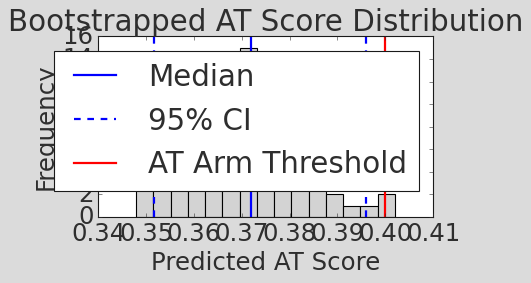

array([0.38727835, 0.40198368, 0.36241047, 0.37411317, 0.36722629,
       0.35910888, 0.37403332, 0.36532925, 0.35864838, 0.37091031,
       0.36327851, 0.3629064 , 0.39820589, 0.37267482, 0.36703578,
       0.37855585, 0.37571332, 0.36418918, 0.3500733 , 0.35899597,
       0.37938433, 0.3612848 , 0.37236596, 0.35307468, 0.39951373,
       0.3778433 , 0.37165126, 0.37490917, 0.37052244, 0.34791651,
       0.37331219, 0.38101587, 0.36579165, 0.37935384, 0.38077497,
       0.37389435, 0.37645604, 0.39079785, 0.36442693, 0.38086415,
       0.38084312, 0.35735374, 0.36597094, 0.35705751, 0.36744857,
       0.38698315, 0.35429959, 0.3660784 , 0.36106307, 0.379392  ,
       0.37183053, 0.36006768, 0.3673895 , 0.39365469, 0.37792891,
       0.3628112 , 0.37555234, 0.36716099, 0.35524182, 0.37286713,
       0.38143345, 0.38118573, 0.38177438, 0.38113486, 0.37445483,
       0.36679935, 0.37494674, 0.38934028, 0.37133136, 0.38119864,
       0.368931  , 0.37018111, 0.37146895, 0.38633571, 0.37156

In [ ]:
calculate_clinical_decision_stability(fitObj=fit_obj, bootstrap_df=bootstrap_df, base_model=tmp_model, at_threshold=0.40)

In [ ]:
def generate_5_patient_stability_table(patient_list, model_dir, at_threshold=0.40):
    print(f"Generating Decision Stability Table for {len(patient_list)} patients...")
    results_list = []
    
    for pat_id in patient_list:
        print(f"\n--- Processing Patient {pat_id} ---")
        
        # 1. Load the existing fit object
        curr_out_dir = os.path.join(model_dir, f"patient{pat_id}")
        fit_obj_path = os.path.join(curr_out_dir, "fitObj_fit_0.p")
        
        try:
            with open(fit_obj_path, "rb") as f:
                fit_obj = pickle.load(f)
        except FileNotFoundError:
            print(f"Failed (No fit_obj found).")
            continue
            
        # 2. Run the bootstrap (suppressing output to keep console clean)
        bootstrap_df = perform_bootstrap(
            fitObj=fit_obj, 
            n_bootstraps=100, 
            shuffle_params=False,
            model_to_observation_map={"TumourSize": 'PSA'}, 
            show_progress=True
        )
        
        # 3. Propagate to AT Score
        at_scores = []
        for i in range(len(bootstrap_df)):
            curr_params = fit_obj.params.copy()
            for var in bootstrap_df.columns:
                if var == "SSR": continue
                if var in curr_params:
                    curr_params[var].value = bootstrap_df[var].iloc[i]
            
            # Calculate downstream score using the unpacked dictionary
            score = calc_AT_score(patientId=pat_id, **curr_params.valuesdict())
            at_scores.append(score)
            
        at_scores = np.array(at_scores)
        
        # 4. Calculate Statistics
        median_at = np.median(at_scores)
        ci_lower = np.percentile(at_scores, 2.5)
        ci_upper = np.percentile(at_scores, 97.5)
        
        # 5. Directional Decision Stability
        if median_at > at_threshold:
            prob_stable = np.mean(at_scores > at_threshold) * 100
            assigned_arm = "AT"
        else:
            prob_stable = np.mean(at_scores <= at_threshold) * 100
            assigned_arm = "CT"
            
        results_list.append({
            "PatientId": pat_id,
            "AssignedArm": assigned_arm,
            "MedianScore": median_at,
            "CI_Lower": ci_lower,
            "CI_Upper": ci_upper,
            "Stability": prob_stable
        })
        print("Done.")
        
    return pd.DataFrame(results_list)

model_name = "LotkaVolterraModel"
working_dir = os.path.join(out_dir, model_name)

stability_df = generate_5_patient_stability_table(patientIds, working_dir)
print(stability_df)

Generating Decision Stability Table for 5 patients...

--- Processing Patient 12 ---


100%|██████████| 100/100 [01:33<00:00,  1.07it/s]


Done.

--- Processing Patient 20 ---


100%|██████████| 100/100 [02:43<00:00,  1.63s/it]


Done.

--- Processing Patient 25 ---


100%|██████████| 100/100 [03:10<00:00,  1.90s/it]


Done.

--- Processing Patient 78 ---


100%|██████████| 100/100 [03:45<00:00,  2.26s/it]


Done.

--- Processing Patient 85 ---


100%|██████████| 100/100 [02:23<00:00,  1.43s/it]

Done.
   PatientId AssignedArm  MedianScore  CI_Lower  CI_Upper  Stability
0         12          CT     0.268737  0.255577  0.291578      100.0
1         20          AT     0.495319  0.456599  0.574963      100.0
2         25          AT     0.438991  0.415600  0.495292      100.0
3         78          AT     0.551727  0.491581  0.650063      100.0
4         85          CT     0.366395  0.352779  0.398084       98.0


## Bootstrapping for all Biomarker Predictions

In [48]:
def calc_threshold_benefit(ave_n, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=(ave_n / params['K']), **params)

def predict_at50_ttp_simp(**kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    n_crit = params['n0']/2
    ave_n = (n_crit +  params['n0']) / 2
    benefit = calc_threshold_benefit(ave_n, **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

def predict_at_threshold_ttp_simp(n_crit, **kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    benefit = calc_delta_benefit(kappa=n_crit / params['K'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [49]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
def get_ttp(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['PSA'] < 1.2 * dataDf['PSA'].iloc[0]]
    return dataDf['Time'].iloc[-1]

print(get_ttp(patientIds[0]))

839


In [50]:
def get_N_star(patientId, **kwargs):
    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    N_star = dataDf['PSA'].mean()
    interval = dataDf['Time'].diff().mean()
    overshoot = calc_average_overshoot(int(interval), N_star, **kwargs)
    return N_star + overshoot

param_set = trunc_df.loc[trunc_df.PatientId == patientIds[2]].iloc[0].to_dict()
print(get_N_star(patientIds[2], **param_set))

0.7199379859510979


In [51]:
def fraction_time_below_threshold(dataDf, threshold, time_col="Time", value_col="PSA"):
    tmp = (
        dataDf[[time_col, value_col]]
        .dropna()
        .sort_values(time_col)
        .groupby(time_col, as_index=False)[value_col].mean()
    )

    if len(tmp) < 2:
        return np.nan

    t = tmp[time_col].to_numpy(dtype=float)
    y = tmp[value_col].to_numpy(dtype=float)

    dt = np.diff(t)
    valid = dt > 0
    if not np.any(valid):
        return np.nan

    y0 = y[:-1][valid]
    y1 = y[1:][valid]
    dt = dt[valid]

    all_under = (y0 <= threshold) & (y1 <= threshold)
    all_over = (y0 > threshold) & (y1 > threshold)
    crossing = ~(all_under | all_over)

    under_time = np.sum(dt[all_under])

    if np.any(crossing):
        alpha = (threshold - y0[crossing]) / (y1[crossing] - y0[crossing])
        alpha = np.clip(alpha, 0.0, 1.0)

        # If segment starts below threshold, time below is alpha * dt.
        # If segment starts above threshold, time below is (1 - alpha) * dt.
        crossing_under_time = np.where(
            y0[crossing] <= threshold,
            alpha * dt[crossing],
            (1.0 - alpha) * dt[crossing],
        )
        under_time += np.sum(crossing_under_time)

    total_time = np.sum(dt)
    return under_time / total_time

In [52]:
def predict_clinical_ttp(patientId, **kwargs):
    param_set = kwargs

    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    threshold = 2.5 / dataDf['PSA_raw'].iloc[0]  # 2.5 ng/mL normalized by initial PSA
    N_star = dataDf[dataDf['PSA']>=threshold]['PSA'].mean()
    at_ttp = predict_at_threshold_ttp_simp(param_set['n0'] * N_star, **param_set)
    ct_ttp = predict_ct_ttp(**param_set)


    fraction_under_threshold = fraction_time_below_threshold(dataDf, threshold)
    weighted_increment = (1 - fraction_under_threshold) * (at_ttp - ct_ttp)
    return ct_ttp + weighted_increment


param_set = trunc_df.loc[trunc_df.PatientId == patientIds[2]].iloc[0].to_dict()
print(predict_clinical_ttp(patientIds[2], **param_set))

1344.2809838021676


In [53]:
def predict_clinical_mdd(patientId, **kwargs):
    param_set = kwargs

    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    threshold = 2.5 / dataDf['PSA_raw'].iloc[0]  # 2.5 ng/mL normalized by initial PSA
    N_star = dataDf[dataDf['PSA']>=threshold]['PSA'].mean()
    tau = dataDf['Time'].diff().mean()

    return predict_drug_benefit(n_crit=N_star, tau=tau, **param_set)


param_set = trunc_df.loc[trunc_df.PatientId == patientIds[0]].iloc[0].to_dict()
print(predict_clinical_mdd(patientIds[0], **param_set))

0.6155137919210416


In [ ]:
def generate_comprehensive_bootstrap_results(patient_list, model_dir, at_threshold=0.40):
    print(f"Generating Comprehensive Bootstrap Table...")
    results_list = []
    
    # Dictionaries to store raw distributions for plotting
    plot_data = {'AT': {}, 'eMDD': {}, 'eTTP': {}}
    
    for pat_id in patient_list:
        print(f"\n--- Processing Patient {pat_id} ---")
        curr_out_dir = os.path.join(model_dir, f"patient{pat_id}")
        fit_obj_path = os.path.join(curr_out_dir, "fitObj_fit_0.p")
        
        with open(fit_obj_path, "rb") as f:
            fit_obj = pickle.load(f)
            
        bootstrap_df = perform_bootstrap(
            fitObj=fit_obj, n_bootstraps=100, shuffle_params=False,
            model_to_observation_map={"TumourSize": 'PSA'}, show_progress=True 
        )
        
        at_scores, emdd_scores, ettp_scores = [], [], []
        
        for i in range(len(bootstrap_df)):
            curr_params = fit_obj.params.copy()
            for var in bootstrap_df.columns:
                if var == "SSR": continue
                if var in curr_params:
                    curr_params[var].value = bootstrap_df[var].iloc[i]
            
            p_dict = curr_params.valuesdict()
            
            # 1. AT Score
            at_scores.append(calc_AT_score(patientId=pat_id, **p_dict))
            # 2. eMDD (Replace calc_eMDD with your actual function name)
            emdd_scores.append(predict_clinical_mdd(patientId=pat_id, **p_dict))
            # 3. eTTP
            ettp_scores.append(predict_clinical_ttp(patientId=pat_id, **p_dict))
            
        # Filter NaNs and calculate stats
        def get_stats(scores_list):
            valid = [s for s in scores_list if np.isfinite(s)]
            if not valid: return np.nan, np.nan, np.nan, []
            return np.median(valid), np.percentile(valid, 2.5), np.percentile(valid, 97.5), valid
            
        at_med, at_l, at_u, at_valid = get_stats(at_scores)
        md_med, md_l, md_u, md_valid = get_stats(emdd_scores)
        tp_med, tp_l, tp_u, tp_valid = get_stats(ettp_scores)
        
        # Save raw distributions for the CI plots later
        plot_data['AT'][pat_id] = (at_med, at_l, at_u)
        plot_data['eMDD'][pat_id] = (md_med, md_l, md_u)
        plot_data['eTTP'][pat_id] = (tp_med, tp_l, tp_u)
        
        # Calculate Stability (AT Score specific)
        prob_stable = np.mean(np.array(at_valid) > at_threshold) * 100 if at_med > at_threshold else np.mean(np.array(at_valid) <= at_threshold) * 100
        
        results_list.append({
            "PatientId": pat_id,
            "AT_Median": at_med, "AT_CI_L": at_l, "AT_CI_U": at_u,
            "eMDD_Median": md_med, "eMDD_CI_L": md_l, "eMDD_CI_U": md_u,
            "eTTP_Median": tp_med, "eTTP_CI_L": tp_l, "eTTP_CI_U": tp_u,
            "Stability": prob_stable
        })
        
    return pd.DataFrame(results_list), plot_data

comprehensive_df, plot_distributions = generate_comprehensive_bootstrap_results(patientIds, working_dir)

Generating Comprehensive Bootstrap Table...

--- Processing Patient 12 ---


100%|██████████| 100/100 [01:28<00:00,  1.13it/s]



--- Processing Patient 20 ---


100%|██████████| 100/100 [03:05<00:00,  1.86s/it]



--- Processing Patient 25 ---


100%|██████████| 100/100 [07:55<00:00,  4.75s/it]



--- Processing Patient 78 ---


100%|██████████| 100/100 [03:52<00:00,  2.33s/it]



--- Processing Patient 85 ---


100%|██████████| 100/100 [02:12<00:00,  1.32s/it]


In [ ]:
print(comprehensive_df)

   PatientId  AT_Median   AT_CI_L   AT_CI_U  eMDD_Median  eMDD_CI_L  \
0         12   0.270091  0.258640  0.287905     0.624955   0.586524   
1         20   0.495319  0.460123  0.546392     0.351693   0.315290   
2         25   0.438991  0.409622  0.495190     0.361897   0.339813   
3         78   0.551727  0.511349  0.665585     0.311065   0.292339   
4         85   0.366395  0.352728  0.388886     0.448984   0.441119   

   eMDD_CI_U  eTTP_Median    eTTP_CI_L    eTTP_CI_U  Stability  
0   0.645635   587.894302   550.807027   659.023916      100.0  
1   0.391057  1144.225423   956.017223  1308.260848      100.0  
2   0.387635  1292.126692  1095.919301  1402.679077       99.0  
3   0.338020  1234.858244  1096.115526  1322.534837      100.0  
4   0.464782   906.749776   823.098248   924.548960      100.0  


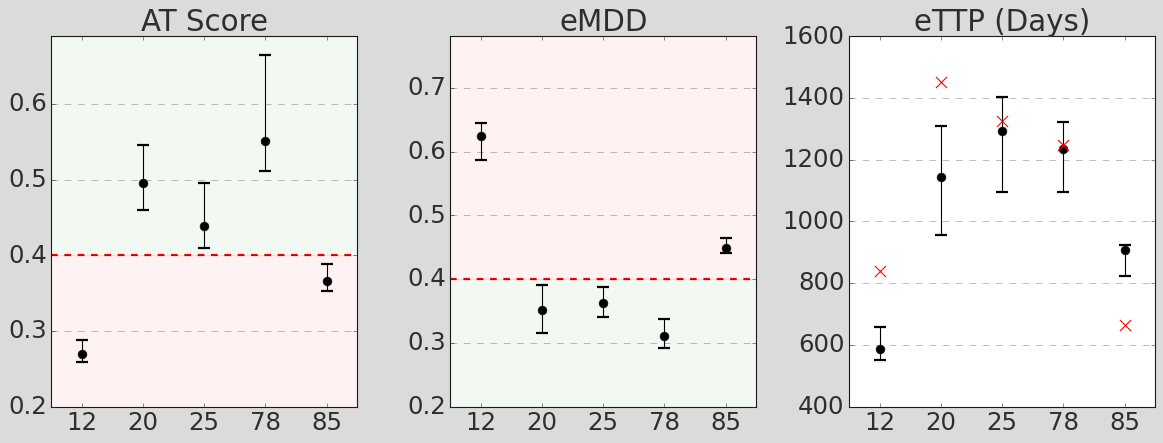

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_bootstrapped_cis(plot_data, true_ttps_dict, at_threshold=0.40):
    patients = list(plot_data['AT'].keys())
    x_pos = np.arange(len(patients))
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    metrics = ['AT', 'eMDD', 'eTTP']
    titles = ['AT Score', 'eMDD', 'eTTP (Days)']
    
    for idx, metric in enumerate(metrics):
        ax = axes[idx]
        
        # Extract medians and calculate error bar lengths (median - lower, upper - median)
        medians = [plot_data[metric][p][0] for p in patients]
        err_lower = [plot_data[metric][p][0] - plot_data[metric][p][1] for p in patients]
        err_upper = [plot_data[metric][p][2] - plot_data[metric][p][0] for p in patients]
        
        # Plot the error bars
        ax.errorbar(x_pos, medians, yerr=[err_lower, err_upper], fmt='o', color='black', 
                    capsize=5, capthick=2, markersize=8, label='Median (95% CI)')
        
        ax.set_xticks(x_pos)
        ax.set_xlim([-0.5, len(patients)-0.5])
        ax.set_xticklabels(patients)
        ax.set_title(titles[idx])
        
        # Add respective thresholds and true values
        if metric == 'AT' or metric == 'eMDD':
            ax.axhline(at_threshold, color='red', linestyle='--', linewidth=2, label=f'CT/AT Threshold ({at_threshold})')
            # Shade the background to visually separate CT and AT regions
            ax.axhspan(0, at_threshold, color='red' if metric == 'AT' else 'green', alpha=0.05)
            ax.axhspan(at_threshold, max(medians)*1.25, color='green' if metric == 'AT' else 'red', alpha=0.05)
            ax.set_ylim([0.2, max(medians)*1.25])
            
        elif metric == 'eTTP':
            true_vals = [true_ttps_dict.get(p, np.nan) for p in patients]
            ax.scatter(x_pos, true_vals, color='red', marker='x', s=100, zorder=5, label='True Clinical TTP')
            
        # ax.legend(loc='best')
        ax.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig("figures/bootstrapped_biomarkers_cis.pdf", dpi=300, bbox_inches='tight')
    plt.show()

# Execution:
# Ensure you have your true TTP dictionary defined
true_ttps_dict = {12: 839, 20: 1451, 25: 1327, 78: 1248, 85: 665}
plot_bootstrapped_cis(plot_distributions, true_ttps_dict)

In [59]:
keep_ids = patientIds

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_44316/2908774830.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{100*float(x.get_text()):.0f}" for x in ax.get_yticklabels()])


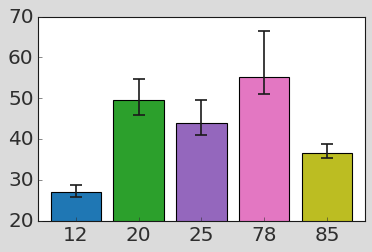

In [108]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
    
def doubling_benefit_wrapper(row):
    kappa = 0.5 * row.n0 / row.K  # 50% threshold, accounting for kappa scaling
    return calc_delta_benefit(kappa=kappa, **row.to_dict())
  
doubling = [doubling_benefit_wrapper(trunc_df[trunc_df.PatientId == n].iloc[0])
            for n in keep_ids]

# Extract asymmetric error bars from the bootstrap dictionary
err_lower_at = [plot_distributions['AT'][n][0] - plot_distributions['AT'][n][1] for n in keep_ids]
err_upper_at = [plot_distributions['AT'][n][2] - plot_distributions['AT'][n][0] for n in keep_ids]

# Add yerr and error styling to the bar plot
plt.bar(range(len(doubling)), doubling, yerr=[err_lower_at, err_upper_at], 
        color=[cols[n] for n in range(len(doubling))], 
        capsize=5, edgecolor='black', error_kw={'elinewidth': 1.5, 'capthick': 1.5})

ax.set_xticks(range(len(doubling)))
ax.set_xticklabels(keep_ids)
ax.set_xlim(-0.6, len(doubling)-0.4)
ax.set_ylim(0.2, 0.7)
ax.set_yticklabels([f"{100*float(x.get_text()):.0f}" for x in ax.get_yticklabels()])
ax.tick_params(top=False, right=False)

# plt.xlabel("Patient ID"); plt.ylabel("Delta AT Score")

plt.tight_layout()
plt.savefig("figures/fig4_delta_at_scores.pdf")
plt.show()

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_44316/3812681012.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{100*float(x.get_text()):.0f}" for x in ax.get_yticklabels()])


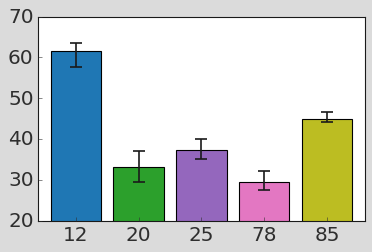

In [109]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

mdd_vals = [predict_drug_benefit(tau=30, n_crit=0.5 * trunc_df[trunc_df.PatientId == n].n0.values[0],
                                 **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict())
            for n in keep_ids]

# Extract asymmetric error bars from the bootstrap dictionary
err_lower_mdd = [plot_distributions['eMDD'][n][0] - plot_distributions['eMDD'][n][1] for n in keep_ids]
err_upper_mdd = [plot_distributions['eMDD'][n][2] - plot_distributions['eMDD'][n][0] for n in keep_ids]

# Add yerr and error styling to the bar plot
plt.bar(range(len(mdd_vals)), mdd_vals, yerr=[err_lower_mdd, err_upper_mdd], 
        color=[cols[n] for n in range(len(mdd_vals))], 
        capsize=5, edgecolor='black', error_kw={'elinewidth': 1.5, 'capthick': 1.5})

ax.set_xticks(range(len(mdd_vals)))
ax.set_xticklabels(keep_ids)
ax.set_xlim(-0.6, len(mdd_vals)-0.4)
ax.set_ylim(0.2, 0.7)
ax.set_yticklabels([f"{100*float(x.get_text()):.0f}" for x in ax.get_yticklabels()])
ax.tick_params(top=False, right=False)

# plt.xlabel("Patient ID"); plt.ylabel("eMDD Score")

plt.tight_layout()
plt.savefig("figures/fig4_eMDD_scores.pdf")
plt.show()

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_44316/1636300799.py:40: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "--o" (-> linestyle='--'). The keyword argument will take precedence.
  error_bars = ax.errorbar(x_jittered, y_exp, yerr=y_err, fmt='--o', color=cols[i],


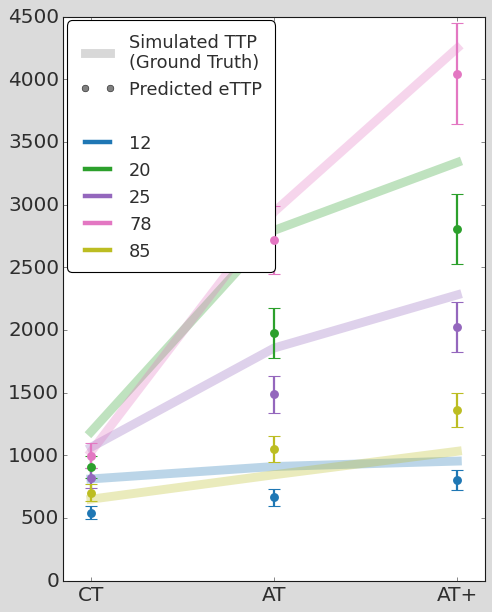

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Define the data (using the arrays you already calculated)
real_ct = [predict_ct_ttp(**df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
real_at = [predict_at_threshold_ttp(tau=60, **df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
real_at_plus = [predict_at_threshold_ttp(tau=30, **df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]

exp_ct = [predict_ct_ttp(**trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
exp_at = [predict_at_threshold_ttp(tau=60, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
exp_at_plus = [predict_at_threshold_ttp(tau=30, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]

# Note: Replace these placeholder error arrays with your actual bootstrap/analytical errors!
# Assuming symmetrical errors for visualization (e.g., +/- 10% of the prediction)
err_ct = [val * 0.10 for val in exp_ct] 
err_at = [val * 0.10 for val in exp_at]
err_at_plus = [val * 0.10 for val in exp_at_plus]

labels = ['CT', 'AT', 'AT+']
x = np.arange(len(labels))

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(6.5, 8))

# 2. Plot the trajectories
for i, patient_id in enumerate(keep_ids):
    # Apply a tiny horizontal jitter so error bars don't perfectly overlap and occlude each other
    jitter = (i - len(keep_ids)/2) * 0.03
    x_jittered = x #+ jitter
    
    y_real = [real_ct[i], real_at[i], real_at_plus[i]]
    y_exp = [exp_ct[i], exp_at[i], exp_at_plus[i]]
    y_err = [err_ct[i], err_at[i], err_at_plus[i]]
    
    # Plot Ground Truth (Simulated) - Thick, transparent, solid
    ax.plot(x_jittered, y_real, linestyle='-', color=cols[i], linewidth=8, alpha=0.3, zorder=1)
    
    # Plot Predicted (Estimated) - Thin, crisp, dashed with error bars
    error_bars = ax.errorbar(x_jittered, y_exp, yerr=y_err, fmt='--o', color=cols[i], 
                             linewidth=2, markersize=8, capsize=5, capthick=2, linestyle='',
                             markeredgecolor=None, markeredgewidth=1, elinewidth=2, zorder=5)
    error_bars[0].set_markeredgewidth(0)

# 3. Aesthetics & Readability
ax.set_xticks(x)
ax.set_xticklabels(labels)
# ax.set_ylabel("Time to Progression (Days)")
ax.set_xlim(-0.15, 2.15)

# Remove top/right spines and add y-grid for easy value reading
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# ax.grid(axis='y', linestyle='--', alpha=0.4)

# 4. Customizing the Legend for a non-mathematical audience
# We create proxy artists to clearly explain the line styles vs the colors


legend_elements = [
    Line2D([0], [0], color='gray', lw=8, alpha=0.3, label='Simulated TTP \n(Ground Truth)'),
    Line2D([0], [0], color='gray', lw=2, linestyle='', marker='o', label='Predicted eTTP'),
    Line2D([0], [0], color='white', lw=0, label=' ')] # Spacer

for i, p_id in enumerate(keep_ids):
    legend_elements.append(Line2D([0], [0], color=cols[i], lw=4, label=f'{p_id}'))

legend = ax.legend(handles=legend_elements, loc='upper left', #bbox_to_anchor=(1.02, 1), 
                   fontsize=16, frameon=True, edgecolor='black')
legend.get_frame().set_boxstyle('Round', pad=0.3, rounding_size=0.3)

plt.tight_layout()
plt.savefig("figures/fig4_TTP_clinical_trajectory.pdf")
plt.show()

## PSA Sampling Frequency

In [133]:
import os
import pickle
import random
import numpy as np
import pandas as pd
from tqdm import tqdm
from lmfit import Parameters, minimize
import matplotlib.pyplot as plt
import seaborn as sns

def run_rarefaction_bootstrap(patient_list, data_path, model_dir, at_threshold=0.40, min_points=3, iterations=50):
    print("Starting Rarefaction-Bootstrap Analysis...")
    results_list = []
    
    solver_kws = {'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10, 'suppressOutputB':False}
    optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8, 'max_nfev':200, 'nan_policy':'omit', 'verbose':0}
    
    for pat_id in patient_list:
        print(f"\n--- Processing Patient {pat_id} ---")
        
        # 1. Load the "Ground Truth" full-data fit object
        fit_obj_path = os.path.join(model_dir, f"patient{pat_id}", "fitObj_fit_0.p")
        with open(fit_obj_path, "rb") as f:
            full_fit_obj = pickle.load(f)
            
        residual_variance = np.sum(np.square(full_fit_obj.residual)) / full_fit_obj.nfree
        
        # Calculate Ground Truth Decision
        gt_params = full_fit_obj.params.valuesdict()
        gt_at_score = calc_AT_score(patientId=pat_id, **gt_params)
        gt_decision = "AT" if gt_at_score >= at_threshold else "CT"
        
        # 2. Load and clean the actual clinical data
        training_data_df = LoadPatientData(pat_id, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()
        last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
        full_cycle1_data = training_data_df[:last_cycle1_index+2].copy()
        
        max_points = len(full_cycle1_data)
        
        if max_points < min_points:
            print(f"Patient {pat_id} only has {max_points} points. Skipping.")
            continue
            
        # 3. Perform Rarefaction loop
        for n_points in range(min_points, max_points + 1):
            stable_decisions = 0
            valid_fits = 0
            
            for _ in range(iterations):
                # Always keep Baseline (Day 1) at index 0
                indices_to_sample = list(range(1, max_points))
                sampled_indices = random.sample(indices_to_sample, n_points - 1)
                selected_indices = [0] + sorted(sampled_indices)
                
                downsampled_df = full_cycle1_data.iloc[selected_indices].copy()
                
                # Create Synthetic Noisy Data (matching your perform_bootstrap logic)
                # Idealized prediction = Actual data - Residual
                ideal_predictions = downsampled_df['PSA'].values - full_fit_obj.residual[selected_indices]
                
                # Inject noise N(0, var) - but keep baseline clean so 'n0' doesn't blow up
                noise = np.random.normal(loc=0, scale=np.sqrt(residual_variance), size=n_points)
                noise[0] = 0.0 
                downsampled_df['PSA'] = ideal_predictions + noise
                
                # 4. Setup Parameters for refitting
                params = Parameters()
                params.add('turnover', min=0.01, max=1., vary=True)
                params.add('K', value=3, min=2.5, max=5, vary=True)
                params.add('fR', value=1e-5, vary=False)
                params.add('cost', value=0.1, vary=False)
                params.add('rS', value=0.027, vary=False)
                params.add('n0', value=downsampled_df.PSA.iloc[0], vary=False) 
                params.add('rR', expr='(1-cost)*rS', vary=False)
                params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
                params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
                params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
                params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)
                
                tmp_model = LotkaVolterraModel()
                tmp_model.SetParams(**params)
                
                try:
                    # Refit to the noisy, sparse data
                    fit_obj = minimize(residual, params, args=(downsampled_df, tmp_model, 
                                                              "PSA", solver_kws), **optimiser_kws)
                    
                    p_dict = fit_obj.params.valuesdict()
                    at_score = calc_AT_score(patientId=pat_id, **p_dict)
                    downsampled_decision = "AT" if at_score >= at_threshold else "CT"
                    
                    if downsampled_decision == gt_decision:
                        stable_decisions += 1
                    valid_fits += 1
                    
                except Exception as e:
                    # Catch failures where LM cannot fit highly sparse/noisy anomalies
                    pass
            
            # Calculate final stability % for this number of points
            stability = (stable_decisions / valid_fits * 100) if valid_fits > 0 else np.nan
            
            results_list.append({
                "PatientId": pat_id,
                "N_Points": n_points,
                "Total_Available": max_points,
                "Decision_Stability": stability
            })
            
    return pd.DataFrame(results_list)

# --- EXECUTION ---
# Run 100 iterations per point-count to get smooth percentages
rarefaction_df = run_rarefaction_bootstrap(patientIds, data_path, working_dir, iterations=100)

Starting Rarefaction-Bootstrap Analysis...

--- Processing Patient 12 ---



--- Processing Patient 20 ---

--- Processing Patient 25 ---

--- Processing Patient 78 ---

--- Processing Patient 85 ---


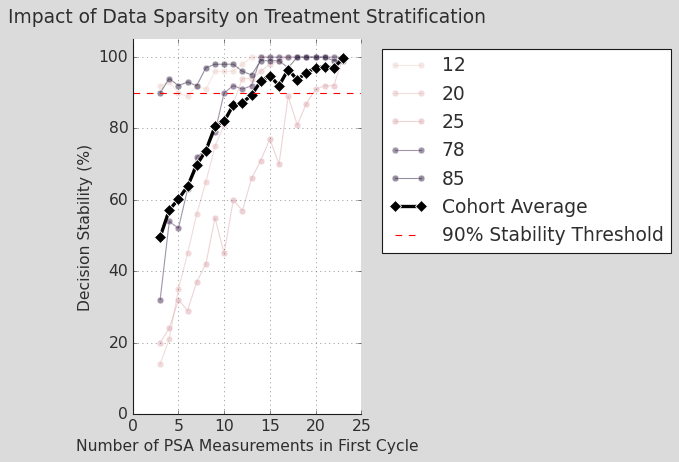

In [134]:
plt.rcParams['font.size'] = 14
plt.figure(figsize=(8, 6))

# Plot individual patient curves
sns.lineplot(data=rarefaction_df, x='N_Points', y='Decision_Stability', 
             hue='PatientId', marker='o', alpha=0.5, legend="full")

# Plot the cohort average
sns.lineplot(data=rarefaction_df, x='N_Points', y='Decision_Stability', 
             color='black', linewidth=3, errorbar=None, label='Cohort Average', marker='D', markersize=8)

# Formatting
plt.axhline(90, color='red', linestyle='--', label='90% Stability Threshold')
plt.xlabel("Number of PSA Measurements in First Cycle")
plt.ylabel("Decision Stability (%)")
plt.title("Impact of Data Sparsity on Treatment Stratification", pad=15)
plt.ylim(0, 105)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("figures/SI_rarefaction_stability.pdf", dpi=300)
plt.show()

In [54]:
# rarefaction_df.to_csv("rarefaction_bootstrap_results.csv", index=False)
rarefaction_df = pd.read_csv("rarefaction_bootstrap_results.csv")

In [55]:
print(rarefaction_df.columns)

Index(['PatientId', 'N_Points', 'Total_Available', 'Decision_Stability'], dtype='object')


In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- 1. Compute Cycle_Duration_Days for each patient ---
duration_dict = {}
unique_patients = rarefaction_df['PatientId'].unique()

print("Extracting Cycle 1 Durations...")
for patientId in unique_patients:
    # Load data using your provided logic
    training_data_df = LoadPatientData(patientId, data_path)
    training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()

    # Find the last index of Cycle 1
    last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
    
    # Calculate duration (Assuming 'Time' is your temporal column in days)
    start_time = training_data_df.loc[0, 'Time']
    end_time = training_data_df.loc[last_cycle1_index, 'Time']
    duration_days = end_time - start_time
    
    duration_dict[patientId] = duration_days

# Map durations to the rarefaction dataframe
rarefaction_df['Cycle_Duration_Days'] = rarefaction_df['PatientId'].map(duration_dict)

# Calculate Frequency (Measurements per month, assuming 1 month = 30.44 days)
rarefaction_df['Freq_per_Month'] = rarefaction_df['N_Points'] / (rarefaction_df['Cycle_Duration_Days'] / 30.44)


# --- 2. Create the Figure 
n = len(unique_patients)
cols = [plt.cm.tab10(i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd']


Extracting Cycle 1 Durations...


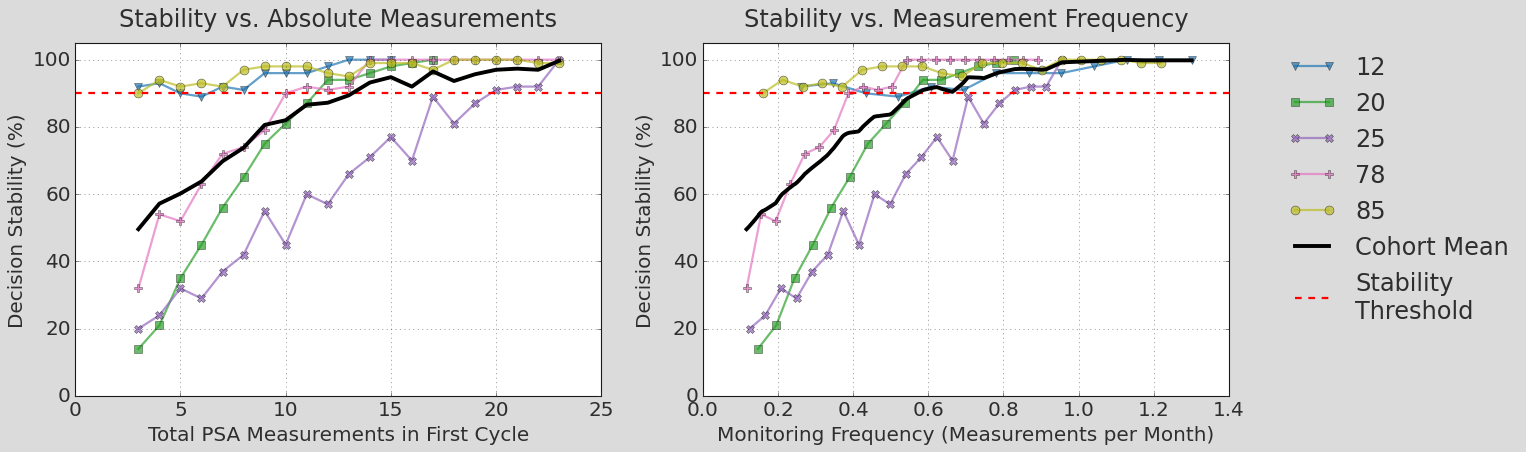

In [58]:

plt.rcParams['font.size'] = 18
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---- Panel A: Absolute Number of Points ----
ax1 = axes[0]
for i, pat_id in enumerate(unique_patients):
    pat_data = rarefaction_df[rarefaction_df['PatientId'] == pat_id].sort_values('N_Points')
    ax1.plot(pat_data['N_Points'], pat_data['Decision_Stability'], 
             color=cols[i], marker=markers[i % len(markers)], markersize=8,
             linewidth=2, alpha=0.7, label=pat_id)

# Calculate and plot cohort average for absolute points
avg_abs = rarefaction_df.groupby('N_Points')['Decision_Stability'].mean().reset_index()
ax1.plot(avg_abs['N_Points'], avg_abs['Decision_Stability'], 
         color='black', linewidth=3.5, marker='', markersize=8, label='Cohort Mean', zorder=10)

ax1.axhline(90, color='red', linestyle='--', linewidth=2, label='Stability\nThreshold')
ax1.set_xlabel("Total PSA Measurements in First Cycle")
ax1.set_ylabel("Decision Stability (%)")
ax1.set_title("Stability vs. Absolute Measurements", pad=15)
ax1.set_ylim(0, 105)
# ax1.spines['top'].set_visible(False)
# ax1.spines['right'].set_visible(False)
ax1.grid(True, linestyle=':', alpha=0.7)

# ---- Panel B: Measurement Frequency ----
ax2 = axes[1]
for i, pat_id in enumerate(unique_patients):
    pat_data = rarefaction_df[rarefaction_df['PatientId'] == pat_id].sort_values('Freq_per_Month')
    ax2.plot(pat_data['Freq_per_Month'], pat_data['Decision_Stability'], 
             color=cols[i], marker=markers[i % len(markers)], markersize=8, 
             linewidth=2, alpha=0.7) # Labels omitted to avoid duplicate legend

# 1. Define a common, uniform frequency grid across the whole plot range
min_freq = rarefaction_df['Freq_per_Month'].min()
max_freq = rarefaction_df['Freq_per_Month'].max()
common_freqs = np.linspace(min_freq, max_freq, 200)

# 2. Interpolate each patient's curve onto this shared grid
interpolated_stabilities = []
for pat_id in unique_patients:
    pat_data = rarefaction_df[rarefaction_df['PatientId'] == pat_id].dropna(subset=['Freq_per_Month', 'Decision_Stability'])
    pat_data = pat_data.sort_values('Freq_per_Month') # np.interp requires sorted x values
    
    # Linear interpolation (extrapolates flat for values outside the patient's min/max range)
    interp_y = np.interp(common_freqs, pat_data['Freq_per_Month'], pat_data['Decision_Stability'])
    interpolated_stabilities.append(interp_y)

# 3. Calculate the true point-by-point mean across all patients
cohort_avg_stab = np.mean(interpolated_stabilities, axis=0)

# 4. Plot the smoothed cohort average
ax2.plot(common_freqs, cohort_avg_stab, color='black', linewidth=3.5, label='Cohort Average', zorder=10)

ax2.axhline(90, color='red', linestyle='--', linewidth=2)
ax2.set_xlabel("Monitoring Frequency (Measurements per Month)")
ax2.set_ylabel("Decision Stability (%)")
ax2.set_title("Stability vs. Measurement Frequency", pad=15)
ax2.set_ylim(0, 105)
# ax2.spines['top'].set_visible(False)
# ax2.spines['right'].set_visible(False)
ax2.grid(True, linestyle=':', alpha=0.7)

# Handle Legend
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.9), loc='upper left', frameon=False)

plt.tight_layout()
plt.savefig("figures/SI_rarefaction_dual_panel.pdf", dpi=300, bbox_inches='tight')
plt.show()


In [25]:

# --- 3. Compute the Minimum Threshold Table ---
print("\n--- Operational Requirements for 90% Decision Stability ---")
print(f"{'Patient ID':<12} | {'Cycle Length (Months)':<22} | {'Min Measurements':<18} | {'Min Frequency (per Month)'}")
print("-" * 85)

table_results = []

for pat_id in unique_patients:
    # Sort from highest number of points down to lowest
    pat_data = rarefaction_df[rarefaction_df['PatientId'] == pat_id].sort_values('N_Points', ascending=False)
    
    cycle_months = pat_data['Cycle_Duration_Days'].iloc[0] / 30.44
    min_req_points = np.nan
    min_req_freq = np.nan
    
    # Conservative threshold scan
    # The moment stability drops below 90, the PREVIOUS number of points was our minimum safe threshold.
    for idx, row in pat_data.iterrows():
        if row['Decision_Stability'] < 90.0:
            break
        min_req_points = row['N_Points']
        min_req_freq = row['Freq_per_Month']
        
    table_results.append((pat_id, cycle_months, min_req_points, min_req_freq))
    
    print(f"Patient {pat_id:<4} | {cycle_months:<22.1f} | {min_req_points:<18} | {min_req_freq:.1f}")

# Cohort Summary Stats
valid_points = [x[2] for x in table_results if not np.isnan(x[2])]
valid_freqs = [x[3] for x in table_results if not np.isnan(x[3])]

if valid_points and valid_freqs:
    print("-" * 85)
    print(f"COHORT MAX   | -                      | {np.max(valid_points):<18} | {np.max(valid_freqs):.1f}")
else:
    print("Warning: Could not compute a valid cohort maximum (stability never reached 90%).")


--- Operational Requirements for 90% Decision Stability ---
Patient ID   | Cycle Length (Months)  | Min Measurements   | Min Frequency (per Month)
-------------------------------------------------------------------------------------
Patient 12   | 11.5                   | 7.0                | 0.6
Patient 20   | 20.5                   | 12.0               | 0.6
Patient 25   | 24.1                   | 20.0               | 0.8
Patient 78   | 25.8                   | 10.0               | 0.4
Patient 85   | 18.9                   | 3.0                | 0.2
-------------------------------------------------------------------------------------
COHORT MAX   | -                      | 20.0               | 0.8
